# Preprocessing thí điểm: resize ảnh nguồn hay tìm mặt lại?
**Đồ án CV nâng cao · Nhóm A/B/C · 28/10/2026**

Notebook này mở đầu bước 4, sau notebook chia tập và protocol. Câu hỏi đặt ra: **hai cách chuẩn bị ảnh có tạo đúng đầu vào cho encoder và giữ đủ mẫu số không?** Notebook chưa trả lời cách nào nhận diện tốt hơn. Chỉ dùng ảnh **DigiFace validation**; không đọc ảnh train/test hay ROF/MFR2.

Hai cách được so:
- **A – resize thẳng:** ảnh DigiFace vốn đã crop sẵn quanh mặt, resize về 160 × 160.
- **B – tìm mặt lại:** chạy MTCNN trên ảnh, crop theo bbox rồi resize về 160 × 160.

Không chạy encoder, không chọn ngưỡng, không train. Ảnh gốc giữ nguyên; pixel/tensor của pilot nằm riêng trong `notebook_outputs`. Các quyết định chờ nhóm (gallery đã rõ mặt chưa, các ca nhãn/box) vẫn để mở.

## 1. Mục tiêu và hợp đồng cần giữ

1. Mỗi ảnh được đọc đúng bytes, xử lý EXIF/màu/alpha theo quy tắc cố định và tạo tensor RGB `float32[3,160,160]`.
2. Chuẩn hóa đúng như facenet-pytorch: **(pixel − 127,5) / 128** với pixel thang 0–255. Không chia 255 trước, không dùng chuẩn hóa ImageNet, không chuẩn hóa hai lần.
3. Ảnh không có mặt, nhiều mặt, lỗi đọc hay lỗi tensor đều được giữ lại thành một dòng trạng thái. Không tự chọn mặt lớn nhất, không lấy ảnh query thay cho ảnh gallery lỗi.
4. Đo tỷ lệ chuẩn bị được theo từng vai trò ảnh và so hai cách trên cùng một ảnh. Sai khác pixel hay diện tích bbox không cho biết cách nào nhận diện tốt hơn.

MTCNN mặc định chỉ crop và resize theo bbox, **không căn mặt theo 5 điểm landmark**. Điểm detector là điểm tin cậy của mô hình, không phải xác suất đúng người hay tỷ lệ bị che.

In [1]:
from __future__ import annotations
from pathlib import Path
from collections import defaultdict
from datetime import datetime,timezone
import hashlib,json,os,time,platform,inspect,importlib.metadata
import numpy as np
import pandas as pd
from PIL import Image,ImageOps,ImageDraw,ImageFont
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display,Markdown,Code
import torch
from facenet_pytorch import MTCNN
from facenet_pytorch.models.mtcnn import fixed_image_standardization
from facenet_pytorch.models.utils.detect_face import extract_face,crop_resize

def find_root():
    candidates=[Path(os.environ['CV_PROJECT_ROOT'])] if os.environ.get('CV_PROJECT_ROOT') else []
    for parent in [Path.cwd(),*Path.cwd().parents]:
        candidates += [parent]
    for p in candidates:
        if (p/'ban_giao_nhom/preprocessing/Preprocessing_thi_diem_validation.ipynb').is_file():return p.resolve()
    raise FileNotFoundError('Mở notebook trong thư mục dự án hoặc đặt biến môi trường CV_PROJECT_ROOT.')

ROOT=find_root();HERE=ROOT/'ban_giao_nhom/preprocessing';OUT=HERE/'notebook_outputs'
TAB,FIG,CACHE=OUT/'tables',OUT/'figures',OUT/'cache'
for p in [OUT,TAB,FIG,CACHE]:p.mkdir(parents=True,exist_ok=True)
ROLE_PATH=ROOT/'ban_giao_nhom/protocol/notebook_outputs/tables/05_image_roles_draft.csv'
SEED=20261028
CONFIG={
 'version':'preprocess_val_pilot_v1','seed':SEED,'partition':'val','source':'DigiFace',
 'known_identities':20,'unknown_identities':40,'known_queries_per_identity':4,'unknown_queries_per_identity':4,
 'image_size':160,'margin':0,'min_face_size':20,'thresholds':[0.6,0.7,0.7],'factor':0.709,
 'keep_all':True,'post_process':True,'direct_resize':'PIL_BILINEAR',
 'color':'EXIF_transpose_then_RGB; nonopaque_alpha_composite_white',
 'standardization':'(pixel_float_0_255-127.5)/128.0',
 'face_policy':'exactly_one_or_return_failure; no_face_selection',
 'cache_policy':'reuse_only_exact_fingerprint_and_artifact_hash_match',
 'tuning_scope':'validation_only; no_recognition_score',
}
DEVICE='cuda:0' if torch.cuda.is_available() else 'cpu'
torch.set_num_threads(4)
np.random.seed(SEED);torch.manual_seed(SEED)
plt.rcParams.update({'font.family':'Arial','figure.dpi':110,'axes.unicode_minus':False,
 'axes.spines.top':False,'axes.spines.right':False})
pd.set_option('display.max_columns',16);pd.set_option('display.max_rows',28)
STARTED=time.perf_counter()

def sha(p):
 h=hashlib.sha256()
 with Path(p).open('rb') as f:
  for b in iter(lambda:f.read(2**20),b''):h.update(b)
 return h.hexdigest()
def digest(obj):return hashlib.sha256(json.dumps(obj,sort_keys=True,ensure_ascii=False).encode()).hexdigest()
def save(frame,name):
 frame.to_csv(TAB/(name+'.csv'),index=False,encoding='utf-8-sig');return frame
def json_out(obj,name):
 (OUT/name).write_text(json.dumps(obj,ensure_ascii=False,indent=2),encoding='utf-8')
def finish(fig,name):
 for ext in ['png','svg']:fig.savefig(FIG/(name+'.'+ext),bbox_inches='tight',dpi=160)
 display(fig);plt.close(fig)
def vn(x,digits=0):return f'{x:,.{digits}f}'.replace(',','_').replace('.',',').replace('_','.')
def stable(values,context):
 return sorted(set(values),key=lambda x:(hashlib.sha256(f'{SEED}|{context}|{x}'.encode()).hexdigest(),x))
def sync():
 if DEVICE.startswith('cuda'):torch.cuda.synchronize()

ENV={'python':platform.python_version(),'pandas':pd.__version__,'numpy':np.__version__,
 'pillow':Image.__version__,'torch':torch.__version__,
 'torchvision':importlib.metadata.version('torchvision'),
 'facenet_pytorch':importlib.metadata.version('facenet-pytorch'),'device':DEVICE,
 'cuda_runtime':torch.version.cuda,'gpu':torch.cuda.get_device_name(0) if DEVICE.startswith('cuda') else None,
 'network_access':'none','raw_write':False,'recognition_inference':False}
display(pd.DataFrame([ENV]).T.rename(columns={0:'Giá trị'}))

H:\Nam tu\Hoc Ki 1\CV nang cao\Đồ Án\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Giá trị
python,3.11.9
pandas,2.2.3
numpy,1.26.4
pillow,10.2.0
torch,2.2.2+cu121
torchvision,0.17.2+cu121
facenet_pytorch,2.6.0
device,cuda:0
cuda_runtime,12.1
gpu,NVIDIA GeForce RTX 4060 Laptop GPU


### Chạy lại

Chọn kernel Python 3.11 của `.venv` rồi Restart Kernel → Run All. Notebook luôn hash lại các ảnh mẫu. Cache chỉ được dùng khi danh sách validation, mẫu chọn, cấu hình, mã nguồn notebook, code thư viện và trọng số detector đều khớp; ghi rõ lượt chạy dùng cache hay tính mới.

Thời gian đo ở phần 12 là chi phí chạy pilot trên ảnh 112 × 112, không phải độ trễ webcam.

## 2. Chỉ định cohort trước khi chạy detector

**Mẫu chính:** 20 người known của validation (đủ 3 ảnh gallery + 4 ảnh query mỗi người) và 40 người unknown (4 ảnh query mỗi người), tổng 300 ảnh. Ảnh được chọn theo seed và hash của ID, không dựa vào điểm detector, độ nét hay độ sáng. Mẫu này để phủ đủ các vai trò ảnh, không đại diện cho chất lượng của toàn bộ validation.

**Mẫu stress:** các ảnh validation mà QA đã gắn cờ detector thất bại (`review_detector_policy_failure`), dùng để xem lỗi có lặp lại không. Tỷ lệ của mẫu này báo riêng, không gộp vào mẫu chính; ảnh thuộc cả hai mẫu chỉ chạy detector một lần.

Không dùng ảnh train/test hay ảnh thật. Gallery ở đây là ảnh DigiFace chưa gán nhãn che, chưa được gọi là "gallery ảnh rõ".

In [2]:
CRITICAL=['image_id','source','identity','condition','path','sha256','pixel_sha256','canonical_identity',
 'guard_group','partition','identity_role','role','qa_reasons']
def read_validation():
 m=pd.read_csv(ROLE_PATH,dtype=str,keep_default_na=False)
 v=m[m.partition.eq('val') & m.source.eq('DigiFace')][CRITICAL].sort_values('image_id').reset_index(drop=True)
 assert v.image_id.is_unique and v.path.is_unique and v.partition.eq('val').all() and v.source.eq('DigiFace').all()
 return v
def frame_hash(frame):return hashlib.sha256(frame.to_csv(index=False,lineterminator='\n').encode()).hexdigest()
V=read_validation();VAL_SHA=frame_hash(V)
known_ids=stable(V[V.identity_role.eq('known')].canonical_identity,'pilot_known_ids')[:CONFIG['known_identities']]
unknown_ids=stable(V[V.identity_role.eq('unknown')].canonical_identity,'pilot_unknown_ids')[:CONFIG['unknown_identities']]
assert len(known_ids)==CONFIG['known_identities'] and len(unknown_ids)==CONFIG['unknown_identities']
selected=[]
for identity in known_ids:
 g=V[V.canonical_identity.eq(identity)]
 galleries=g[g.role.eq('gallery')]
 assert len(galleries)==3
 selected.extend(galleries.image_id)
 q=g[g.role.eq('known_query')]
 selected.extend(stable(q.image_id,identity+'_known_query')[:CONFIG['known_queries_per_identity']])
for identity in unknown_ids:
 q=V[V.canonical_identity.eq(identity) & V.role.eq('unknown_query')]
 selected.extend(stable(q.image_id,identity+'_unknown_query')[:CONFIG['unknown_queries_per_identity']])
representative=set(selected)
assert len(representative)==300
stress=set(V[V.qa_reasons.str.contains('review_detector_policy_failure')].image_id)
S=V[V.image_id.isin(representative|stress)].copy()
S['in_representative']=S.image_id.isin(representative)
S['in_stress']=S.image_id.isin(stress)
S=S.sort_values('image_id').reset_index(drop=True)
assert set(S.image_id)<=set(V.image_id)
assert not set(known_ids)&set(unknown_ids)
assert S.groupby('guard_group').role.nunique().le(1).all()
save(S,'01_pilot_selection')
selection_summary=pd.concat([
 S[S.in_representative].groupby('role').agg(images=('image_id','size'),identities=('canonical_identity','nunique')).assign(cohort='representative'),
 S[S.in_stress].groupby('role').agg(images=('image_id','size'),identities=('canonical_identity','nunique')).assign(cohort='stress_existing_alert'),
]).reset_index()
save(selection_summary,'01_cohort_summary');display(selection_summary)
display(Markdown(f'Chạy trên **{vn(len(S))} ảnh validation duy nhất**: {vn(len(representative))} ảnh mẫu chính và '
 f'{vn(len(stress))} ảnh stress; giao hai cohort = {vn(len(representative&stress))} ảnh.'))

,role,images,identities,cohort
0,gallery,60,20,representative
1,known_query,80,20,representative
2,unknown_query,160,40,representative
3,gallery,1,1,stress_existing_alert
4,known_query,1,1,stress_existing_alert
5,unknown_query,6,5,stress_existing_alert


Chạy trên **308 ảnh validation duy nhất**: 300 ảnh mẫu chính và 8 ảnh stress; giao hai cohort = 0 ảnh.

## 3. Đọc ảnh: bytes, EXIF, alpha và RGB

Ảnh chỉ được mở sau khi SHA-256 khớp manifest. `ImageOps.exif_transpose` xử lý hướng ảnh trước mọi phép crop. Nếu ảnh có pixel trong suốt thì ghép lên nền trắng, tránh việc bỏ kênh alpha làm hiện nền đen; bảng dưới cho biết quy tắc nào thực sự được dùng với dữ liệu hiện tại.

Resize 112 → 160 chỉ là nội suy, không thêm chi tiết. Ảnh giữ dạng RGB uint8 cho tới lúc chuyển sang tensor float thang 0–255.

In [3]:
def open_rgb(path,expected_sha):
 if sha(path)!=expected_sha:raise ValueError('RAW_SHA_MISMATCH: '+str(path))
 with Image.open(path) as source:
  source.load()
  info={'width_raw':source.width,'height_raw':source.height,'mode_raw':source.mode,
        'exif_orientation':int(source.getexif().get(274,1)),
        'has_alpha':'A' in source.getbands(),'nonopaque_pixels':0}
  transposed=ImageOps.exif_transpose(source)
  if 'A' in transposed.getbands():
   rgba=transposed.convert('RGBA');alpha=np.asarray(rgba.getchannel('A'))
   info['nonopaque_pixels']=int((alpha<255).sum())
   if info['nonopaque_pixels']:
    bg=Image.new('RGBA',rgba.size,(255,255,255,255));transposed=Image.alpha_composite(bg,rgba)
  rgb=transposed.convert('RGB').copy()
  info.update(width_rgb=rgb.width,height_rgb=rgb.height)
 return rgb,info

raw_rows=[]
for row in S.itertuples():
 im,meta=open_rgb(ROOT/row.path,row.sha256)
 raw_rows.append({'image_id':row.image_id,'sha256_now':sha(ROOT/row.path),'matches_manifest':True,**meta})
raw_check=save(pd.DataFrame(raw_rows),'02_raw_and_color_integrity')
assert raw_check.matches_manifest.all()
assert raw_check.width_rgb.eq(112).all() and raw_check.height_rgb.eq(112).all()
display(raw_check.groupby(['width_raw','height_raw','mode_raw','exif_orientation','nonopaque_pixels']).size().rename('images').reset_index())
display(Markdown(f'Đã hash mới **{vn(len(raw_check))} ảnh mẫu**. Đây không phải quét mới toàn bộ 80.000 ảnh DigiFace.'))

,width_raw,height_raw,mode_raw,exif_orientation,nonopaque_pixels,images
0,112,112,RGBA,1,0,308


Đã hash mới **308 ảnh mẫu**. Đây không phải quét mới toàn bộ 80.000 ảnh DigiFace.

## 4. Đối chiếu code thư viện và khởi tạo detector

In trực tiếp mã nguồn của phiên bản thư viện đang cài để làm bằng chứng: `fixed_image_standardization`, `crop_resize`, `extract_face`, `MTCNN.extract`. Thư viện crop bằng PIL rồi resize BILINEAR; `extract_face` chuyển ảnh sang mảng float32 nên tensor giữ thang 0–255. Nếu tự dùng `ToTensor` trên ảnh uint8 (ra thang 0–1) rồi áp công thức trên thì sẽ sai.

Hash mã nguồn và trọng số detector được đưa vào dấu vân tay cache. Trọng số MTCNN có sẵn trong thư viện nên không cần mạng.

In [4]:
library_sources={name:inspect.getsource(func) for name,func in [
 ('fixed_image_standardization',fixed_image_standardization),('crop_resize',crop_resize),
 ('extract_face',extract_face),('MTCNN.extract',MTCNN.extract),('MTCNN.detect',MTCNN.detect)]}
source_hashes={name:hashlib.sha256(src.encode()).hexdigest() for name,src in library_sources.items()}
for name in ['fixed_image_standardization','crop_resize']:
 display(Markdown('### '+name));display(Code(library_sources[name],language='python'))
save(pd.DataFrame([{'function':name,'source_sha256':value} for name,value in source_hashes.items()]),'03_library_source_hashes')
mtcnn=MTCNN(image_size=CONFIG['image_size'],margin=CONFIG['margin'],min_face_size=CONFIG['min_face_size'],
 thresholds=CONFIG['thresholds'],factor=CONFIG['factor'],keep_all=True,post_process=True,
 device=DEVICE).eval()
weights_hasher=hashlib.sha256()
for name,param in sorted(mtcnn.state_dict().items()):
 weights_hasher.update(name.encode());weights_hasher.update(str(tuple(param.shape)).encode())
 weights_hasher.update(str(param.dtype).encode());weights_hasher.update(param.detach().cpu().contiguous().numpy().tobytes())
WEIGHTS_SHA=weights_hasher.hexdigest()
NB_PATH=HERE/'Preprocessing_thi_diem_validation.ipynb'
source_nb=json.loads(NB_PATH.read_text(encoding='utf-8'))
NOTEBOOK_SOURCE_SHA=digest([(c['cell_type'],''.join(c['source'])) for c in source_nb['cells']])
PROVENANCE={'config':CONFIG,'validation_content_sha256':VAL_SHA,'selection_content_sha256':frame_hash(S),
 'library_source_sha256':source_hashes,'detector_state_sha256':WEIGHTS_SHA,
 'notebook_source_sha256':NOTEBOOK_SOURCE_SHA,'environment':ENV,
 'sample_raw_hashes':dict(zip(S.image_id,S.sha256))}
FINGERPRINT=digest(PROVENANCE)
json_out(PROVENANCE,'input_and_code_provenance.json')
display(pd.DataFrame([{'detector_state_sha256':WEIGHTS_SHA,'fingerprint':FINGERPRINT}]).T)

### fixed_image_standardization

def fixed_image_standardization(image_tensor):
    processed_tensor = (image_tensor - 127.5) / 128.0
    return processed_tensor

### crop_resize

def crop_resize(img, box, image_size):
    if isinstance(img, np.ndarray):
        img = img[box[1]:box[3], box[0]:box[2]]
        out = cv2.resize(
            img,
            (image_size, image_size),
            interpolation=cv2.INTER_AREA
        ).copy()
    elif isinstance(img, torch.Tensor):
        img = img[box[1]:box[3], box[0]:box[2]]
        out = imresample(
            img.permute(2, 0, 1).unsqueeze(0).float(),
            (image_size, image_size)
        ).byte().squeeze(0).permute(1, 2, 0)
    else:
        out = img.crop(box).copy().resize((image_size, image_size), Image.BILINEAR)
    return out

,0
detector_state_sha256,1a66cf33957739f72af2a8fea02c357199e2b8859ebb25...
fingerprint,5a17aee505929bb251b63ab6f19d29e22a9fc554422d2b...


## 5. Hai đường xử lý có chung hợp đồng tensor

**Cách A** giữ nguyên khung ảnh nguồn, resize về 160, chuyển RGB uint8 (H×W×C) → tensor float32 (C×H×W) → chuẩn hóa đúng một lần.

**Cách B** tìm **mọi** bbox trong ảnh. Chỉ khi có đúng một bbox hợp lệ mới gọi `MTCNN.extract`; không có mặt hoặc nhiều mặt thì trả về trạng thái lỗi kèm lý do, không tự chọn bbox điểm cao nhất hay lớn nhất. Cả hai cách dùng chung hàm chuẩn hóa của thư viện. Cache lưu **pixel RGB uint8** kèm ID ảnh, khi nạp mới chuẩn hóa (không lưu tensor có giá trị âm như ảnh).

In [5]:
def pixel_tensor(rgb_array):
 arr=np.asarray(rgb_array,dtype=np.uint8)
 if arr.shape!=(160,160,3):raise ValueError('BAD_PIXEL_SHAPE')
 return torch.from_numpy(arr.copy()).permute(2,0,1).to(torch.float32)
def standardize_pixels(rgb_array):return fixed_image_standardization(pixel_tensor(rgb_array))
def validate_tensor(tensor,expected_pixels):
 assert tensor.dtype==torch.float32 and tuple(tensor.shape)==(3,160,160)
 assert torch.isfinite(tensor).all()
 assert float(tensor.min())>=-127.5/128-1e-6 and float(tensor.max())<=(255-127.5)/128+1e-6
 expected=standardize_pixels(expected_pixels)
 assert torch.allclose(tensor,expected,atol=1e-6,rtol=0),'STANDARDIZATION_CONTRACT_MISMATCH'
 return float((tensor-expected).abs().max())
def to_pixels(tensor):
 return ((tensor.detach().cpu()*128+127.5).round().clamp(0,255).to(torch.uint8).permute(1,2,0).numpy())
def face_dispatch(boxes):
 if boxes is None:return 'no_face'
 try:boxes=np.asarray(boxes,dtype=np.float64)  # thư viện trả mảng dtype=object
 except (TypeError,ValueError):return 'invalid_boxes'
 if len(boxes)==0:return 'no_face'
 if boxes.ndim!=2 or boxes.shape[1]!=4 or not np.isfinite(boxes).all():return 'invalid_boxes'
 if len(boxes)>1:return 'multiple_faces'
 if boxes[0,2]<=boxes[0,0] or boxes[0,3]<=boxes[0,1]:return 'invalid_boxes'
 return 'single_face'
def direct_prepare(im):
 pixels=np.asarray(im.resize((160,160),Image.Resampling.BILINEAR),dtype=np.uint8).copy()
 tensor=standardize_pixels(pixels)
 validate_tensor(tensor,pixels)
 return pixels,tensor
def redetect_prepare(im):
 with torch.inference_mode():
  boxes,probs,points=mtcnn.detect(im,landmarks=True)
  status=face_dispatch(boxes)
  if boxes is not None and status=='single_face':boxes=np.asarray(boxes,dtype=np.float32)
  if status!='single_face':return status,boxes,probs,points,None,None
  tensor=mtcnn.extract(im,boxes,save_path=None)[0].detach().cpu()
  # Đối chiếu đường extract() với helper thật của cùng thư viện, không resize lại tensor đã chuẩn hóa.
  raw_tensor=extract_face(im,boxes[0],160,0,save_path=None)
  assert torch.allclose(tensor,fixed_image_standardization(raw_tensor),atol=1e-6,rtol=0)
  pixels=to_pixels(tensor)
  validate_tensor(tensor,pixels)
 return status,boxes,probs,points,pixels,tensor

## 6. Chạy pilot có provenance hoặc dùng cache khớp hoàn toàn

Kết quả gồm một CSV có **mọi ảnh đầu vào**, một file NPZ chứa pixel đã chuẩn bị và metadata khóa bằng dấu vân tay. Ảnh lỗi không có tensor nhưng vẫn có dòng trong bảng trạng thái. Cache chỉ được dùng khi SHA của NPZ/CSV khớp metadata.

Khi tính mới, ảnh đầu tiên được chạy một lần để "làm nóng" GPU và không tính thời gian. Chế độ `computed_now` hay `matching_cache` được ghi lại; nếu dùng cache thì cột thời gian là số đo của lần tạo cache.

In [6]:
META=CACHE/'pilot_cache_meta.json';RESULT_CSV=TAB/'04_per_image_preprocessing.csv';PIXELS=OUT/'pilot_prepared_pixels.npz'
def validate_cache(meta,fingerprint,files):
 if meta.get('fingerprint')!=fingerprint:return False
 for name,path in files.items():
  if not path.is_file() or meta.get('artifact_sha256',{}).get(name)!=sha(path):return False
 return True
cache_files={'results':RESULT_CSV,'pixels':PIXELS}
cache_meta=json.loads(META.read_text(encoding='utf-8')) if META.exists() else {}
CACHE_MODE='matching_cache' if validate_cache(cache_meta,FINGERPRINT,cache_files) else 'computed_now'
if CACHE_MODE=='computed_now':
 first=S.iloc[0]
 warm,_=open_rgb(ROOT/first.path,first.sha256)
 try:
  redetect_prepare(warm);sync()
 except Exception:
  pass # Warm-up không thay status đo thật; lỗi input được ghi lại khi xử lý dưới đây.
 direct_ids=[];direct_arrays=[];redetect_ids=[];redetect_arrays=[];results=[]
 for index,row in enumerate(S.itertuples()):
  record={'image_id':row.image_id,'role':row.role,'canonical_identity':row.canonical_identity,
   'in_representative':row.in_representative,'in_stress':row.in_stress,
   'direct_status':'not_started','redetect_status':'not_started','face_count':0,
   'detector_score':None,'boxes':'[]','landmarks':'[]','box_outside_image':False,
   'clipped_bbox_area_fraction':None,'raw_read_ms':None,'direct_prepare_ms':None,'redetect_prepare_ms':None,
   'direct_tensor_max_error':None,'redetect_tensor_max_error':None,'paired_pixel_mae':None,'error':''}
  try:
   t=time.perf_counter();im,meta=open_rgb(ROOT/row.path,row.sha256);record['raw_read_ms']=(time.perf_counter()-t)*1000
   t=time.perf_counter();dp,dt=direct_prepare(im);record['direct_prepare_ms']=(time.perf_counter()-t)*1000
   direct_ids.append(row.image_id);direct_arrays.append(dp)
   record['direct_status']='prepared_without_detection';record['direct_tensor_max_error']=validate_tensor(dt,dp)
  except Exception as exc:
   record['direct_status']='input_or_direct_error';record['redetect_status']='input_or_direct_error'
   record['error']=type(exc).__name__+': '+str(exc)[:220];results.append(record);continue
  try:
   sync();t=time.perf_counter();status,boxes,probs,points,rp,rt=redetect_prepare(im);sync()
   record['redetect_prepare_ms']=(time.perf_counter()-t)*1000
   record['redetect_status']=status
   record['face_count']=0 if boxes is None else len(boxes)
   record['boxes']=json.dumps([] if boxes is None else np.asarray(boxes).tolist())
   record['landmarks']=json.dumps([] if points is None else np.asarray(points).tolist())
   if probs is not None:
    finite=np.asarray(probs,dtype=float);finite=finite[np.isfinite(finite)]
    record['detector_score']=float(finite.max()) if len(finite) else None
   if status=='single_face':
    x1,y1,x2,y2=map(float,boxes[0]);W,H=im.size
    record['box_outside_image']=bool(x1<0 or y1<0 or x2>W or y2>H)
    record['clipped_bbox_area_fraction']=max(0,min(W,x2)-max(0,x1))*max(0,min(H,y2)-max(0,y1))/(W*H)
    record['paired_pixel_mae']=float(np.abs(dp.astype(float)-rp.astype(float)).mean())
    record['redetect_tensor_max_error']=validate_tensor(rt,rp)
    redetect_ids.append(row.image_id);redetect_arrays.append(rp)
  except Exception as exc:
   record['redetect_status']='detector_or_extract_error';record['error']=type(exc).__name__+': '+str(exc)[:220]
  results.append(record)
  if (index+1)%50==0:print(f'Đã xử lý {index+1}/{len(S)} ảnh validation')
 R=save(pd.DataFrame(results),'04_per_image_preprocessing')
 np.savez_compressed(PIXELS,
  direct_image_ids=np.asarray(direct_ids),direct_rgb=np.stack(direct_arrays),
  redetect_image_ids=np.asarray(redetect_ids),redetect_rgb=np.stack(redetect_arrays) if redetect_arrays else np.empty((0,160,160,3),dtype=np.uint8))
 cache_meta={'fingerprint':FINGERPRINT,'created_at_utc':datetime.now(timezone.utc).isoformat(),
  'provenance':PROVENANCE,'artifact_sha256':{name:sha(path) for name,path in cache_files.items()},
  'mode_when_created':'computed_now','warmup_images':1,'images':len(S)}
 META.write_text(json.dumps(cache_meta,ensure_ascii=False,indent=2),encoding='utf-8')
else:
 R=pd.read_csv(RESULT_CSV,dtype={'image_id':str,'canonical_identity':str})
assert set(R.image_id)==set(S.image_id) and len(R)==len(S)
with np.load(PIXELS,allow_pickle=False) as packed:
 DIDS=packed['direct_image_ids'].tolist();DPIX=packed['direct_rgb'].copy()
 BIDS=packed['redetect_image_ids'].tolist();BPIX=packed['redetect_rgb'].copy()
DIRECT_MAP=dict(zip(DIDS,DPIX));REDETECT_MAP=dict(zip(BIDS,BPIX))
assert set(BIDS)<=set(DIDS) and set(DIDS)==set(R[R.direct_status.eq('prepared_without_detection')].image_id)
assert set(BIDS)==set(R[R.redetect_status.eq('single_face')].image_id)
json_out({'mode':CACHE_MODE,'fingerprint':FINGERPRINT,'raw_sample_hash_checked_now':len(raw_check),
 'detector_inputs_computed_now':len(S) if CACHE_MODE=='computed_now' else 0,
 'detector_inputs_reused':len(S) if CACHE_MODE=='matching_cache' else 0,
 'cache_created_at_utc':cache_meta['created_at_utc'],'latency_values_from':cache_meta['created_at_utc']},'cache_use_summary.json')
display(Markdown(f'Chế độ lượt này: **{CACHE_MODE}**. Có **{vn(len(DIDS))} pixel output A** và '
 f'**{vn(len(BIDS))} pixel output B**; mọi input còn trong bảng status.'))

Đã xử lý 50/308 ảnh validation


Đã xử lý 100/308 ảnh validation


Đã xử lý 150/308 ảnh validation


Đã xử lý 200/308 ảnh validation


Đã xử lý 250/308 ảnh validation


Đã xử lý 300/308 ảnh validation


Chế độ lượt này: **computed_now**. Có **308 pixel output A** và **296 pixel output B**; mọi input còn trong bảng status.

## 7. Tensor online/offline và các bẫy normalization

Khi nạp lại pixel uint8, tensor được chuẩn hóa đúng một lần và so với giá trị tính tay từ pixel. Ngoài kích thước, kiểu dữ liệu và khoảng giá trị, phải so cả nội dung: lỗi chia 255 hay chuẩn hóa hai lần vẫn có thể cho giá trị nằm trong khoảng hợp lệ.

Để chắc bộ kiểm hoạt động, notebook cố tình tạo lỗi trên bản sao trong RAM (không đụng dữ liệu thật): chia 255 trước khi chuẩn hóa, chuẩn hóa hai lần, đảo RGB thành BGR, cache sai dấu vân tay hoặc sai hash, hash ảnh sai. Bộ phân loại số mặt cũng được thử với trường hợp 0 và nhiều bbox.

In [7]:
contract_rows=[]
for method,ids,arrays in [('direct',DIDS,DPIX),('redetect',BIDS,BPIX)]:
 for image_id,pixels in zip(ids,arrays):
  tensor=standardize_pixels(pixels)
  error=validate_tensor(tensor,pixels)
  assert np.array_equal(to_pixels(tensor),pixels)
  contract_rows.append({'method':method,'image_id':image_id,'shape':'3x160x160','dtype':'float32',
   'finite':True,'max_abs_standardization_error':error,'pixel_roundtrip_exact':True,
   'tensor_min':float(tensor.min()),'tensor_max':float(tensor.max())})
tensor_audit=save(pd.DataFrame(contract_rows),'05_tensor_contract')
test_pixels=DPIX[0];correct=standardize_pixels(test_pixels);wrong_scale=fixed_image_standardization(pixel_tensor(test_pixels)/255)
double=fixed_image_standardization(correct)
bgr=standardize_pixels(test_pixels[:,:,::-1])
checks=[]
def reject(name,func):
 try:func()
 except (AssertionError,ValueError):checks.append({'test':name,'passed':True});return
 raise AssertionError('Bộ kiểm không bắt lỗi: '+name)
reject('chia255 trước standardization',lambda:validate_tensor(wrong_scale,test_pixels))
reject('standardize hai lần',lambda:validate_tensor(double,test_pixels))
reject('đảo RGB thành BGR',lambda:validate_tensor(bgr,test_pixels))
reject('raw hash sai phải dừng',lambda:open_rgb(ROOT/S.iloc[0].path,'0'*64))
assert face_dispatch(None)=='no_face' and face_dispatch(np.empty((0,4)))=='no_face'
assert face_dispatch(np.array([[0,0,40,40],[30,30,60,60]]))=='multiple_faces'
assert face_dispatch(np.array([[0,0,40,40]]))=='single_face'
assert face_dispatch(np.array([[0.0,0.0,40.0,40.0]],dtype=object))=='single_face'  # kiểu MTCNN.detect trả về
checks.append({'test':'dispatcher zero/one/multiple bbox','passed':True})
assert not validate_cache(cache_meta,'wrong_fingerprint',cache_files)
bad_meta={**cache_meta,'artifact_sha256':{**cache_meta['artifact_sha256'],'pixels':'0'*64}}
assert not validate_cache(bad_meta,FINGERPRINT,cache_files)
checks += [{'test':'fingerprint stale không dùng cache','passed':True},{'test':'artifact hash sai không dùng cache','passed':True}]
for status in ['no_face','multiple_faces']:
 actual=R[R.redetect_status.eq(status)]
 assert all(x not in REDETECT_MAP for x in actual.image_id)
 checks.append({'test':f'{status}: không tensor, giữ mẫu số thật n={len(actual)}','passed':True})
negative_checks=save(pd.DataFrame(checks),'05_contract_negative_tests')
display(tensor_audit.groupby('method').agg(tensors=('image_id','size'),max_abs_error=('max_abs_standardization_error','max'),
 min_value=('tensor_min','min'),max_value=('tensor_max','max')))
display(negative_checks)

,tensors,max_abs_error,min_value,max_value
method,,,,
direct,308,0.0,-0.996094,0.996094
redetect,296,0.0,-0.996094,0.996094


,test,passed
0,chia255 trước standardization,True
1,standardize hai lần,True
2,đảo RGB thành BGR,True
3,raw hash sai phải dừng,True
4,dispatcher zero/one/multiple bbox,True
5,fingerprint stale không dùng cache,True
6,artifact hash sai không dùng cache,True
7,"no_face: không tensor, giữ mẫu số thật n=11",True
8,"multiple_faces: không tensor, giữ mẫu số thật n=1",True


## 8. Coverage và lỗi: giữ đúng mẫu số theo cohort/role

Cách A chuẩn bị được một ảnh chỉ có nghĩa file resize và chuẩn hóa được, **không có nghĩa ảnh có mặt hợp lệ**. Cách B thành công nghĩa là detector tìm đúng một mặt và crop đúng quy ước, chưa chứng minh đúng người. Bảng dưới báo số ảnh không có mặt / nhiều mặt / lỗi theo từng vai trò, tổng luôn bằng số ảnh đầu vào.

Cột `other_failure` là lỗi phần mềm (đọc ảnh, tensor, extract) và phải bằng 0; phần cuối notebook dừng nếu có lỗi loại này, để bug code không bị ghi nhầm thành "ảnh không dùng được". Tỷ lệ của mẫu stress không phải tỷ lệ lỗi của toàn bộ validation, và tỷ lệ của mẫu chính cũng chưa phải kết quả nhận diện.

,cohort,role,input_images,identities,direct_prepared,redetect_single,no_face,multiple_faces,other_failure,redetect_coverage
0,representative,gallery,60,20,60,60,0,0,0,1.00000
1,representative,known_query,80,20,80,79,1,0,0,0.98750
2,representative,unknown_query,160,40,160,157,2,1,0,0.98125
3,stress_existing_alert,gallery,1,1,1,0,1,0,0,0.00000
4,stress_existing_alert,known_query,1,1,1,0,1,0,0,0.00000
5,stress_existing_alert,unknown_query,6,5,6,0,6,0,0,0.00000


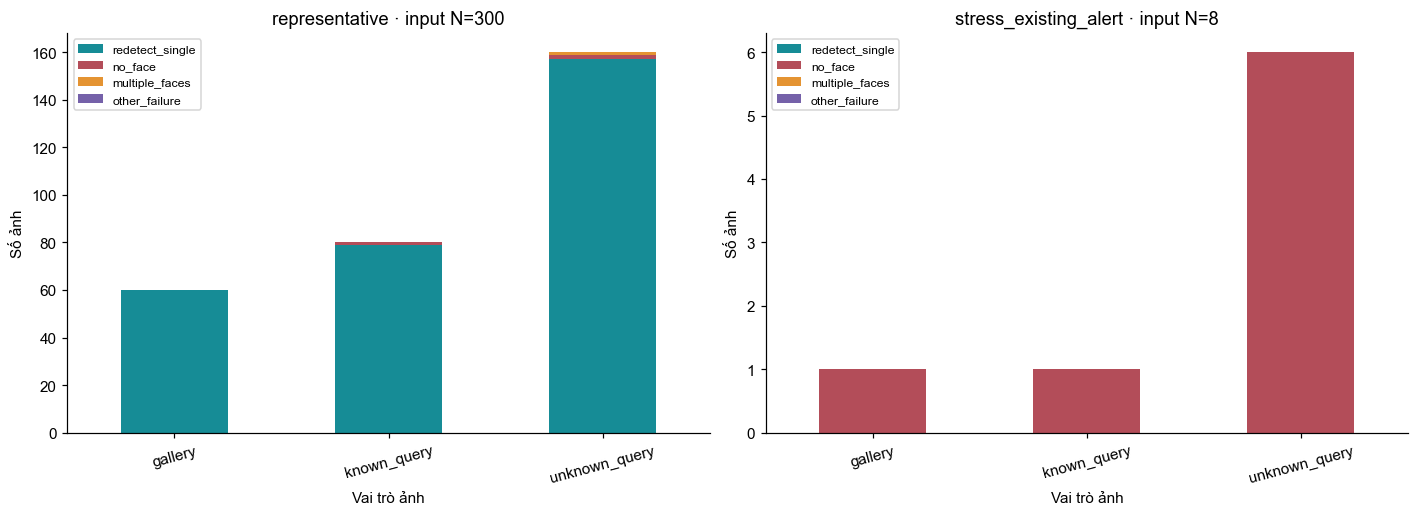

In [8]:
coverage=[]
for cohort,mask in [('representative',R.in_representative),('stress_existing_alert',R.in_stress)]:
 for role,g in R[mask].groupby('role'):
  counts=g.redetect_status.value_counts()
  coverage.append({'cohort':cohort,'role':role,'input_images':len(g),'identities':g.canonical_identity.nunique(),
   'direct_prepared':int(g.direct_status.eq('prepared_without_detection').sum()),
   'redetect_single':int(counts.get('single_face',0)),'no_face':int(counts.get('no_face',0)),
   'multiple_faces':int(counts.get('multiple_faces',0)),
   'other_failure':int((~g.redetect_status.isin(['single_face','no_face','multiple_faces'])).sum()),
   'redetect_coverage':float(g.redetect_status.eq('single_face').mean())})
coverage=save(pd.DataFrame(coverage),'06_coverage_by_cohort_role')
assert (coverage.redetect_single+coverage.no_face+coverage.multiple_faces+coverage.other_failure).eq(coverage.input_images).all()
display(coverage)
fig,axes=plt.subplots(1,2,figsize=(13,4.8))
for ax,cohort in zip(axes,['representative','stress_existing_alert']):
 sub=coverage[coverage.cohort.eq(cohort)].set_index('role')[['redetect_single','no_face','multiple_faces','other_failure']]
 sub.plot.bar(stacked=True,ax=ax,color=['#168C96','#B34D59','#E49332','#7561A9'],rot=15)
 ax.set(title=f'{cohort} · input N={int(sub.to_numpy().sum())}',ylabel='Số ảnh',xlabel='Vai trò ảnh')
 ax.legend(fontsize=8)
fig.tight_layout();finish(fig,'06_coverage_with_failures')

## 9. Enrollment failure trên gallery pilot

Mỗi người known trong mẫu chính có đủ 3 ảnh gallery theo protocol. Nếu một ảnh gallery không chuẩn bị được, người đó bị tính là **đăng ký thất bại (enrollment failure, cấu hình 3/3)**. Không thay ảnh khác, không lấy query làm gallery, không âm thầm giảm số ảnh gallery.

Thông tin này dùng để C thiết kế evaluator: query của người đăng ký thất bại vẫn phải được tính, không được coi người đó là unknown để làm đẹp DIR. Chưa chạy nhận diện nên chưa có DIR/FPIR.

In [9]:
gallery=R[R.in_representative & R.role.eq('gallery')]
enrollment=gallery.groupby('canonical_identity').agg(gallery_inputs=('image_id','size'),
 direct_prepared=('direct_status',lambda x:x.eq('prepared_without_detection').sum()),
 redetect_prepared=('redetect_status',lambda x:x.eq('single_face').sum())).reset_index()
enrollment['direct_enrollment_ok']=enrollment.direct_prepared.eq(3)
enrollment['redetect_enrollment_ok']=enrollment.redetect_prepared.eq(3)
assert enrollment.gallery_inputs.eq(3).all() and len(enrollment)==CONFIG['known_identities']
save(enrollment,'07_gallery_enrollment_3of3')
display(enrollment)
display(Markdown(f'Gallery pilot có **{vn(len(enrollment))} người**; A chuẩn bị đủ 3/3 cho '
 f'**{vn(enrollment.direct_enrollment_ok.sum())} người**, B đủ 3/3 cho **{vn(enrollment.redetect_enrollment_ok.sum())} người**. '
 'Chuẩn bị đủ vẫn chưa chứng nhận gallery clean hoặc đúng nhãn.'))

,canonical_identity,gallery_inputs,direct_prepared,redetect_prepared,direct_enrollment_ok,redetect_enrollment_ok
0,DigiFace:1099,3,3,3,True,True
1,DigiFace:1325,3,3,3,True,True
2,DigiFace:1352,3,3,3,True,True
3,DigiFace:1404,3,3,3,True,True
4,DigiFace:1415,3,3,3,True,True
5,DigiFace:1680,3,3,3,True,True
6,DigiFace:1968,3,3,3,True,True
7,DigiFace:264,3,3,3,True,True
8,DigiFace:330,3,3,3,True,True
9,DigiFace:354,3,3,3,True,True


Gallery pilot có **20 người**; A chuẩn bị đủ 3/3 cho **20 người**, B đủ 3/3 cho **20 người**. Chuẩn bị đủ vẫn chưa chứng nhận gallery clean hoặc đúng nhãn.

## 10. Bbox vượt khung và sai khác giữa hai đầu vào

Với ảnh đã crop sát mặt, bbox của detector vượt khung là bình thường, không có nghĩa annotation sai. Trên **những ảnh có đúng một mặt**, ta đo: phần diện tích bbox nằm trong ảnh, cờ vượt khung và sai khác RGB trung bình giữa A và B.

Sai khác pixel (MAE, thang 0–255) không phải khoảng cách embedding hay độ chính xác. Đổi cách crop làm thay đổi phần nền và chi tiết quanh mặt; ảnh hưởng tới nhận diện chỉ biết được khi chạy B0 + evaluator trên validation.

,cohort,paired_images,bbox_outside_images,pixel_MAE_median,pixel_MAE_p95,clipped_area_fraction_median
0,representative,296,272,32.713893,54.396406,0.599135
1,stress_existing_alert,0,0,NaN,NaN,NaN


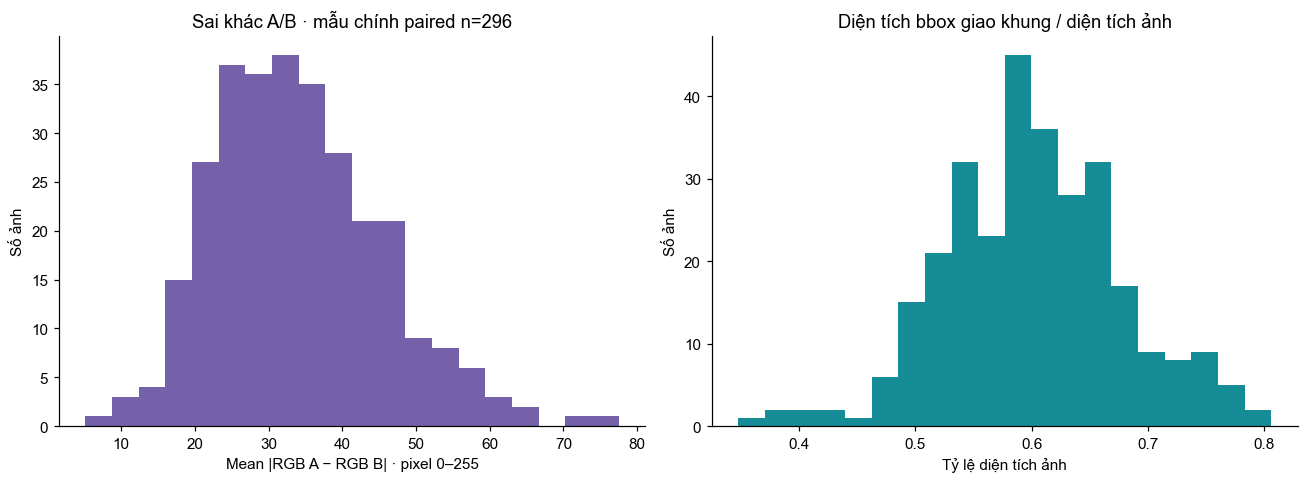

In [10]:
paired=R[R.redetect_status.eq('single_face')].copy()
geometry=save(paired[['image_id','role','canonical_identity','in_representative','in_stress','boxes','box_outside_image',
 'clipped_bbox_area_fraction','paired_pixel_mae']],'08_paired_crop_geometry')
stats=[]
for cohort,mask in [('representative',paired.in_representative),('stress_existing_alert',paired.in_stress)]:
 g=paired[mask]
 stats.append({'cohort':cohort,'paired_images':len(g),'bbox_outside_images':int(g.box_outside_image.sum()),
  'pixel_MAE_median':float(g.paired_pixel_mae.median()) if len(g) else None,
  'pixel_MAE_p95':float(g.paired_pixel_mae.quantile(.95)) if len(g) else None,
  'clipped_area_fraction_median':float(g.clipped_bbox_area_fraction.median()) if len(g) else None})
save(pd.DataFrame(stats),'08_paired_summary');display(pd.DataFrame(stats))
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
main=paired[paired.in_representative]
axes[0].hist(main.paired_pixel_mae,bins=20,color='#7561A9')
axes[0].set(title=f'Sai khác A/B · mẫu chính paired n={len(main)}',xlabel='Mean |RGB A − RGB B| · pixel 0–255',ylabel='Số ảnh')
axes[1].hist(main.clipped_bbox_area_fraction,bins=20,color='#168C96')
axes[1].set(title='Diện tích bbox giao khung / diện tích ảnh',xlabel='Tỷ lệ diện tích ảnh',ylabel='Số ảnh')
fig.tight_layout();finish(fig,'08_paired_crop_geometry')

## 11. Ảnh minh họa thành công và failure

Mỗi hàng gồm ảnh gốc (kèm bbox/landmark của B), kết quả A và kết quả B. Ảnh được chọn có chủ đích: các ca lỗi, các ca A/B khác nhau nhiều nhất và các ca bbox vượt khung. Hình dùng để xem lỗi, không đại diện cho tỷ lệ chung.

Tên hiển thị là nhãn của nguồn. Với ca không có mặt hoặc nhiều mặt, cột B ghi trạng thái lỗi thay vì hiện ảnh.

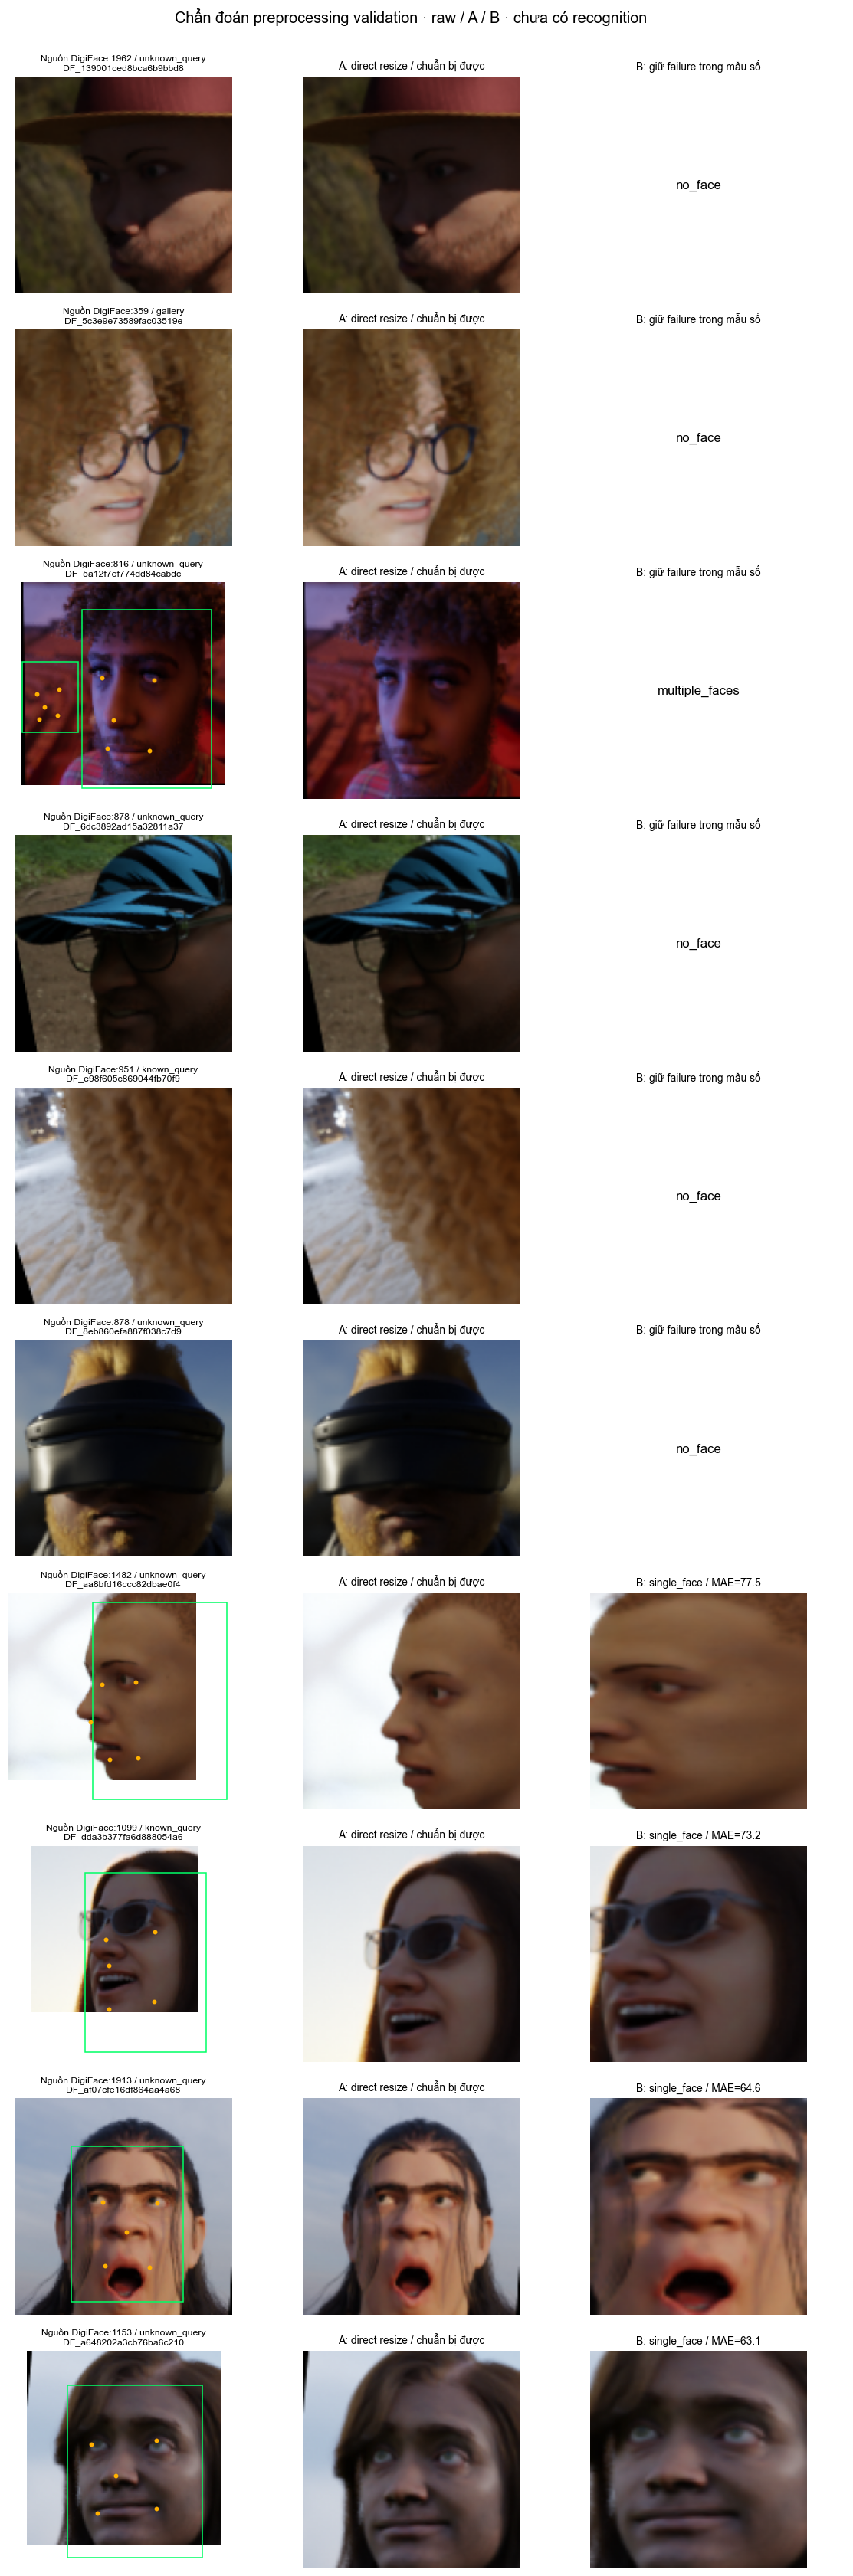

,image_id,source,identity,condition,path,sha256,pixel_sha256,canonical_identity,...,partition,identity_role,role,qa_reasons,in_representative,in_stress,redetect_status,paired_pixel_mae
0,DF_139001ced8bca6b9bbd8,DigiFace,1962,synthetic_unannotated,data/raw/digiface/images_eda/1962/37.png,1f2a1e2da790714c4b910285af61271701dc93732a7b95...,5ebcc018f3075a5390442b85ba59106acfa5f9d4016b0e...,DigiFace:1962,...,val,unknown,unknown_query,review_detector_policy_failure,False,True,no_face,NaN
1,DF_5a12f7ef774dd84cabdc,DigiFace,816,synthetic_unannotated,data/raw/digiface/images_eda/816/17.png,8e72e9969ec5e186594b6389eac16a271ac301a8d5dcdb...,d0fca8f4e4200e7072b1e3276f346a1f2d2af1ec8e3636...,DigiFace:816,...,val,unknown,unknown_query,,True,False,multiple_faces,NaN
2,DF_5c3e9e73589fac03519e,DigiFace,359,synthetic_unannotated,data/raw/digiface/images_eda/359/7.png,a171308e3d9360b0de368621c0895e22aa4ab87715a265...,8e9ac716ec6389140bd36e10a810eade71679273beb561...,DigiFace:359,...,val,known,gallery,review_detector_policy_failure,False,True,no_face,NaN
3,DF_6dc3892ad15a32811a37,DigiFace,878,synthetic_unannotated,data/raw/digiface/images_eda/878/24.png,48ded060705945d7713206053e238fde800b5d0f974e79...,264717913a13e199cafe1cb89e773e3de38c5b3673651f...,DigiFace:878,...,val,unknown,unknown_query,,True,False,no_face,NaN
4,DF_8eb860efa887f038c7d9,DigiFace,878,synthetic_unannotated,data/raw/digiface/images_eda/878/10.png,e11a1089f3e34a103e6fcb21eeb0ca211ccbbb9c68be30...,06ed4e072c6789d389efe95748f29587e0f113b628147b...,DigiFace:878,...,val,unknown,unknown_query,review_detector_policy_failure,False,True,no_face,NaN
5,DF_a648202a3cb76ba6c210,DigiFace,1153,synthetic_unannotated,data/raw/digiface/images_eda/1153/51.png,ca45c281b29491983f8065a8a7de6a73472fe46d8eb485...,ef413162e03f1a264e60a7c33ca559c6d1fea96e20abc8...,DigiFace:1153,...,val,unknown,unknown_query,,True,False,single_face,63.116706
6,DF_aa8bfd16ccc82dbae0f4,DigiFace,1482,synthetic_unannotated,data/raw/digiface/images_eda/1482/46.png,37ef5c09b686ca8a0b42043a947b55b131c4721a20e9a5...,20215c86d9742b4a0388d351be162a06be4339c72ebd1a...,DigiFace:1482,...,val,unknown,unknown_query,,True,False,single_face,77.474388
7,DF_af07cfe16df864aa4a68,DigiFace,1913,synthetic_unannotated,data/raw/digiface/images_eda/1913/31.png,04c670b92ca350204f5bcf05794270d504cf8b23aeb9e5...,10514785de5cd18f25a3204d50e7263eaf6dc71ec826f3...,DigiFace:1913,...,val,unknown,unknown_query,,True,False,single_face,64.621693
8,DF_dda3b377fa6d888054a6,DigiFace,1099,synthetic_unannotated,data/raw/digiface/images_eda/1099/30.png,5cb4ee0252739cfbbfaa746f69384b89fd4e353aa79f70...,621675d2b7562e776e78556e9ab9bb5835ea1b0591becc...,DigiFace:1099,...,val,known,known_query,,True,False,single_face,73.236784
9,DF_e98f605c869044fb70f9,DigiFace,951,synthetic_unannotated,data/raw/digiface/images_eda/951/20.png,c678c707841bfb5268c6fcd299516fec0f86d9ea21c1ff...,abf19b09112eebb56dfc0f92a16ce980e208c8ddb5cc26...,DigiFace:951,...,val,known,known_query,,True,False,no_face,NaN


In [11]:
demo=[]
def take_ids(frame,n,context):return stable(frame.image_id,context)[:n]
failures=R[~R.redetect_status.eq('single_face')]
demo += take_ids(failures,6,'failure_examples')
demo += paired.sort_values(['paired_pixel_mae','image_id'],ascending=[False,True]).image_id.head(4).tolist()
demo += take_ids(paired[paired.box_outside_image],2,'outside_bbox_examples')
demo=list(dict.fromkeys(demo))[:10]
if len(demo)<8:demo += [x for x in take_ids(R,8,'other_examples') if x not in demo][:8-len(demo)]
lookup=S.set_index('image_id');results_lookup=R.set_index('image_id')
fig,axes=plt.subplots(len(demo),3,figsize=(10.6,3.05*len(demo)),squeeze=False)
for row_axes,image_id in zip(axes,demo):
 entry=lookup.loc[image_id];result=results_lookup.loc[image_id]
 im,_=open_rgb(ROOT/entry.path,entry.sha256)
 ax=row_axes[0];ax.imshow(im)
 for box in json.loads(result.boxes):
  x1,y1,x2,y2=box;ax.add_patch(Rectangle((x1,y1),x2-x1,y2-y1,fill=False,edgecolor='#00FF66',linewidth=1))
 for points in json.loads(result.landmarks):
  a=np.asarray(points);ax.scatter(a[:,0],a[:,1],s=8,c='#FFB000')
 ax.set_title(f'Nguồn {entry.canonical_identity} / {entry.role}\n{image_id}',fontsize=8)
 row_axes[1].imshow(DIRECT_MAP[image_id]);row_axes[1].set_title('A: direct resize / chuẩn bị được',fontsize=9)
 if image_id in REDETECT_MAP:
  row_axes[2].imshow(REDETECT_MAP[image_id]);row_axes[2].set_title(f'B: single_face / MAE={result.paired_pixel_mae:.1f}',fontsize=9)
 else:
  row_axes[2].set_facecolor('#F4E5E7');row_axes[2].text(.5,.5,str(result.redetect_status),ha='center',va='center',transform=row_axes[2].transAxes,fontsize=11)
  row_axes[2].set_title('B: giữ failure trong mẫu số',fontsize=9)
 for ax in row_axes:ax.axis('off')
fig.suptitle('Chẩn đoán preprocessing validation · raw / A / B · chưa có recognition',fontsize=13,y=1.001)
fig.tight_layout();finish(fig,'09_raw_direct_redetect_examples')
save(S[S.image_id.isin(demo)].merge(R[['image_id','redetect_status','paired_pixel_mae']],on='image_id',validate='one_to_one'),
 '09_visual_example_selection')

## 12. Thời gian và dung lượng pilot

Đo riêng ba khâu: đọc + hash ảnh, resize (A, chạy CPU) và detect + extract (B, chạy GPU, có đồng bộ CUDA). Thời gian của B gồm cả phần kiểm chéo tensor, nên không phải độ trễ inference tối thiểu; không dùng các số này để suy ra FPS webcam.

File NPZ chỉ chứa pixel uint8 đã chuẩn bị của pilot, kèm ID ảnh; chuẩn hóa khi nạp.

In [12]:
timing=[]
for column in ['raw_read_ms','direct_prepare_ms','redetect_prepare_ms']:
 values=R[column].dropna()
 timing.append({'stage':column,'measured_images':len(values),'median_ms':float(values.median()),
  'p95_ms':float(values.quantile(.95)),'max_ms':float(values.max()),'timing_from_cache_creation':CACHE_MODE=='matching_cache'})
save(pd.DataFrame(timing),'10_pilot_timing');display(pd.DataFrame(timing))
display(pd.DataFrame([{'artifact':'pilot_prepared_pixels.npz','bytes':PIXELS.stat().st_size,
 'direct_images':len(DIDS),'redetect_images':len(BIDS),'dtype':'uint8 RGB; standardize on load','sha256':sha(PIXELS)}]))

,stage,measured_images,median_ms,p95_ms,max_ms,timing_from_cache_creation
0,raw_read_ms,308,1.22880,1.421025,1.7227,False
1,direct_prepare_ms,308,1.62420,1.948560,2.6344,False
2,redetect_prepare_ms,308,22.64755,40.805010,62.4551,False


,artifact,bytes,direct_images,redetect_images,dtype,sha256
0,pilot_prepared_pixels.npz,30452805,308,296,uint8 RGB; standardize on load,af3257cd4237dc2b9f39abec658c9ee3ccc904067e7400...


## 13. Kết luận kỹ thuật, khuyến nghị và phần chưa thể kết luận

**Đề xuất:** với DigiFace (ảnh đã crop sẵn), dùng resize thẳng (A) làm cách nền vì không phụ thuộc vào việc detector chạy lại trên ảnh nhỏ; vẫn phải duyệt gallery và so kết quả nhận diện trên validation trước khi chốt. Với webcam và ảnh toàn cảnh thì vẫn cần detector. ROF/MFR2 chưa được dùng ở đây nên chưa áp kết luận này cho chúng.

Cách A không căn mặt và không kiểm có mặt hay không; cách B tìm được một mặt cũng chưa chắc là đúng người. Không chọn cách xử lý chỉ dựa vào tỷ lệ chuẩn bị được hay MAE: bước B0 + evaluator sẽ so cả hai trên cùng mẫu và cùng mẫu số, tính cả ca lỗi.

**Trước khi xử lý hàng loạt hoặc đánh giá chính thức:** nhóm duyệt gallery và các ca nhãn/box; chốt cách xử lý đăng ký thất bại; đánh version cho cấu hình đầu vào; chạy B0 + evaluator trên validation trước test.

In [13]:
assert frame_hash(read_validation())==VAL_SHA,'Validation roles đổi trong lúc chạy; cần chạy lại pilot.'
assert set(R.image_id)==set(S.image_id) and len(R)==len(S)
assert R.in_representative.sum()==300
assert raw_check.matches_manifest.all() and tensor_audit.finite.all() and tensor_audit.pixel_roundtrip_exact.all()
assert negative_checks.passed.all()
software_errors=R[R.redetect_status.eq('detector_or_extract_error') | R.direct_status.eq('input_or_direct_error')]
assert software_errors.empty,('Lỗi phần mềm, không phải đặc điểm dữ liệu: '+software_errors.error.value_counts().head(3).to_string())
for row in S.itertuples():assert sha(ROOT/row.path)==row.sha256,'Raw thay bytes trong lúc chạy.'
assert validate_cache(cache_meta,FINGERPRINT,cache_files)
policy_input=ROOT/'ban_giao_nhom/quyet_dinh_nhom/input/project_decisions.csv'
recorded=pd.read_csv(policy_input,dtype=str,keep_default_na=False)
p5_rows=recorded[recorded.decision_id.eq('P5')]
p5_confirmed_by_user=(len(p5_rows)==1 and p5_rows.chosen_option.iloc[0]=='direct_resize_digiface'
                      and bool(p5_rows.reviewer.iloc[0].strip()))
p5_status='confirmed_P5' if p5_confirmed_by_user else 'pending_confirmation'
decision_board=save(pd.DataFrame([
 ['Gallery rõ/dữ liệu nền','A/B','Xác nhận bằng ảnh; chưa có quyết định thật ở pilot','pending_human_semantic'],
 ['Áp dụng hold/box/alias','A/C','Tệp group_decisions và evidence riêng; không sửa raw','pending_human_semantic'],
 ['Direct resize cho DigiFace','B/C','Quyết định P5 được đọc từ project_decisions.csv',p5_status],
 ['Enrollment failure 3/3','B/C','Giữ query và báo failure; không thay gallery bằng query','proposed_contract'],
 ['Webcam/cảnh rộng','B/C','Detector + log no/multiple face; cần dữ liệu phiên riêng','not_started'],
],columns=['decision','owner','required_evidence','status']),'11_decisions_and_next_steps')
summary={'status':'validation_pilot_completed_'+p5_status,'scope':'DigiFace val only',
 'policy_input_sha256':sha(policy_input),'P5_confirmed_by_user':p5_confirmed_by_user,
 'checks':'PASS','fresh_kernel_required':True,'cache_mode':CACHE_MODE,
 'raw_images_hashed_now':len(raw_check),'detector_inputs_computed_now':len(S) if CACHE_MODE=='computed_now' else 0,
 'representative_images':len(representative),'stress_images':len(stress),'unique_images':len(S),
 'direct_outputs':len(DIDS),'redetect_outputs':len(BIDS),'redetect_status_counts':R.redetect_status.value_counts().to_dict(),
 'tensor_contracts_checked':len(tensor_audit),'negative_checks_passed':len(negative_checks),
 'known_gallery_identities':len(enrollment),'redetect_enrollment_3of3':int(enrollment.redetect_enrollment_ok.sum()),
 'validation_content_sha256':VAL_SHA,'config_sha256':digest(CONFIG),'fingerprint':FINGERPRINT,
 'notebook_source_sha256':NOTEBOOK_SOURCE_SHA,'raw_modified':False,'labels_changed':False,
 'train_test_external_images_used':False,'recognition_evaluated':False,'threshold_selected':False,
 'training_started':False,'bulk_preprocessing_started':False,'human_approvals_created':False,
 'executed_at_utc':datetime.now(timezone.utc).isoformat(),'elapsed_seconds':round(time.perf_counter()-STARTED,3)}
json_out(summary,'execution_summary.json')
json_out({'version':CONFIG['version'],'scope':'pilot_DigiFace_val_only','official_policy_frozen':False,
 'direct_candidate':'pre_cropped_source: EXIF+RGB+PIL_BILINEAR160+fixed_standardization_once',
 'redetect_candidate':CONFIG,'failure_policy':'exactly_one; retain all failures; no substitution',
 'pixel_cache_sha256':sha(PIXELS),'input_fingerprint':FINGERPRINT,
 'recognition_selection_done':False,'P5_confirmed_by_user':p5_confirmed_by_user,
 'selected_DigiFace_preprocessing':'direct_resize' if p5_confirmed_by_user else None},'preprocessing_candidate_config.json')
artifact_hashes=save(pd.DataFrame([{'path':p.relative_to(OUT).as_posix(),'bytes':p.stat().st_size,'sha256':sha(p)}
 for p in sorted(OUT.rglob('*')) if p.is_file() and p.name!='12_artifact_hashes.csv']), '12_artifact_hashes')
display(decision_board)
display(Markdown(f"""Lượt này kiểm **{vn(len(S))} ảnh validation**: cách A chuẩn bị được **{vn(len(DIDS))}** ảnh,
cách B tìm đúng một mặt ở **{vn(len(BIDS))}** ảnh. **{vn(len(tensor_audit))} tensor** đạt quy ước đầu vào,
**{vn(len(negative_checks))} phép thử lỗi** đều bị bắt đúng. Chế độ chạy: **{CACHE_MODE}**.

**Trạng thái P5** `{p5_status}` theo tệp quyết định nhóm. Kết quả nhận diện B0 nằm trong notebook bước 5. Pilot preprocessing này đo khả năng chuẩn bị ảnh và hợp đồng tensor."""))

,decision,owner,required_evidence,status
0,Gallery rõ/dữ liệu nền,A/B,Xác nhận bằng ảnh; chưa có quyết định thật ở p...,pending_human_semantic
1,Áp dụng hold/box/alias,A/C,Tệp group_decisions và evidence riêng; không s...,pending_human_semantic
2,Direct resize cho DigiFace,B/C,Quyết định P5 được đọc từ project_decisions.csv,confirmed_P5
3,Enrollment failure 3/3,B/C,Giữ query và báo failure; không thay gallery b...,proposed_contract
4,Webcam/cảnh rộng,B/C,Detector + log no/multiple face; cần dữ liệu p...,not_started


Lượt này kiểm **308 ảnh validation**: cách A chuẩn bị được **308** ảnh,
cách B tìm đúng một mặt ở **296** ảnh. **604 tensor** đạt quy ước đầu vào,
**9 phép thử lỗi** đều bị bắt đúng. Chế độ chạy: **computed_now**.

**Trạng thái P5** `confirmed_P5` theo tệp quyết định nhóm. Kết quả nhận diện B0 nằm trong notebook bước 5. Pilot preprocessing này đo khả năng chuẩn bị ảnh và hợp đồng tensor.

## 14. Tệp đầu ra và nguồn

- `tables/01_pilot_selection.csv`: selection và cờ cohort; không chọn lại khi detector fail.
- `tables/02_raw_and_color_integrity.csv`: hash bytes mới và metadata màu/EXIF/alpha của mẫu.
- `tables/04_per_image_preprocessing.csv`: mọi input, status A/B, bbox, lỗi và thời gian.
- `tables/05_*`, `06_*`, `07_*`, `08_*`: tensor contracts, negative checks, coverage, enrollment và paired geometry.
- `pilot_prepared_pixels.npz`: RGB uint8 và image-ID mapping của pilot; load với `allow_pickle=False`, chuẩn hóa khi sử dụng.
- `input_and_code_provenance.json`, `cache_use_summary.json`, `cache/pilot_cache_meta.json`: nguồn và trạng thái cache; không dùng file cache đơn lẻ thiếu metadata.
- `preprocessing_candidate_config.json`: hợp đồng ứng viên có version, chưa khóa policy chính thức.
- `execution_summary.json`, `tables/12_artifact_hashes.csv`: kết quả thực và hash artifact. Validation JSON do runner tạo là bằng chứng bổ sung.

Nguồn kỹ thuật trực tiếp là code `facenet_pytorch.models.mtcnn` và `models.utils.detect_face` của phiên bản cài đặt, có hash ở phần 4. Tài liệu nguồn: [facenet-pytorch](https://github.com/timesler/facenet-pytorch), [MTCNN implementation](https://github.com/timesler/facenet-pytorch/blob/master/models/mtcnn.py), [extract/crop implementation](https://github.com/timesler/facenet-pytorch/blob/master/models/utils/detect_face.py). Số liệu tính từ dữ liệu cục bộ, không lấy mô tả thư viện làm kết quả thực nghiệm.